<a href="https://colab.research.google.com/github/sanchit-Thakur/ML-COURSE/blob/main/Machine_Learning_course.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

In [21]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")
print(df.head(8))
print(df.info)

    Student_ID  Age  ... Academic_Performance_GPA Overall_Impact
0  STU_2024000   19  ...                     2.73        Neutral
1  STU_2024001   19  ...                     3.21     Beneficial
2  STU_2024002   17  ...                     3.00        Neutral
3  STU_2024003   16  ...                     3.42     Beneficial
4  STU_2024004   17  ...                     3.41     Beneficial
5  STU_2024005   16  ...                     3.21     Beneficial
6  STU_2024006   20  ...                     3.72     Beneficial
7  STU_2024007   19  ...                     3.37     Beneficial

[8 rows x 16 columns]
<bound method DataFrame.info of        Student_ID  Age  ... Academic_Performance_GPA Overall_Impact
0     STU_2024000   19  ...                     2.73        Neutral
1     STU_2024001   19  ...                     3.21     Beneficial
2     STU_2024002   17  ...                     3.00        Neutral
3     STU_2024003   16  ...                     3.42     Beneficial
4     STU_2024004   

In [22]:
cols = ("flength" , "fwidth" , "fconc" , "fconc1" , "fasym" , "fm3long", "falpha")
df = pd.read_csv("/content/Social_media_impact_on_life.csv", names = cols)
df.head()

,,,,,,,,,flength,fwidth,fconc,fconc1,fasym,fm3long,falpha
Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.0,Neutral
STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial


In [23]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")

print("Unique classes in 'Overall_Impact':", df["Overall_Impact"].unique())

Unique classes in 'Overall_Impact': ['Neutral' 'Beneficial' 'Negative']


In [24]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")

impact_map = {"Beneficial": 1, "Neutral": 2, "Negative": 0}
df["Overall_Impact"] = df["Overall_Impact"].map(impact_map).astype(int)

print(df["Overall_Impact"].value_counts())

Overall_Impact
1    3681
2     654
0     165
Name: count, dtype: int64


In [25]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,2
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,1
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,2
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,1
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,1


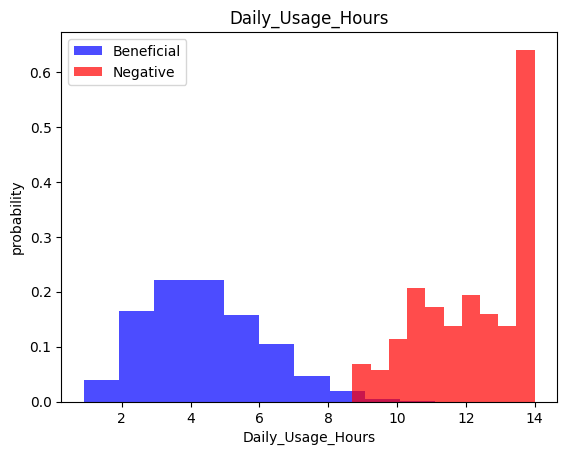

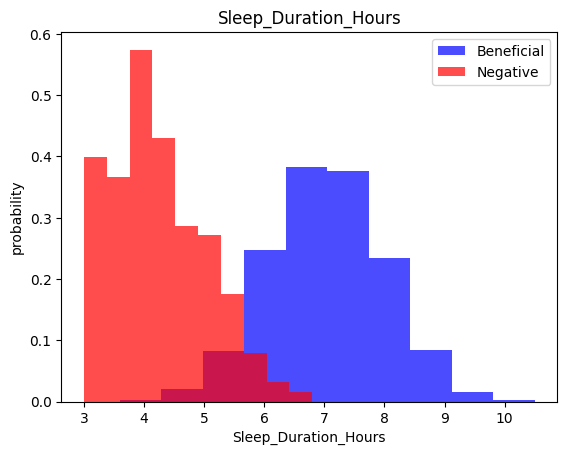

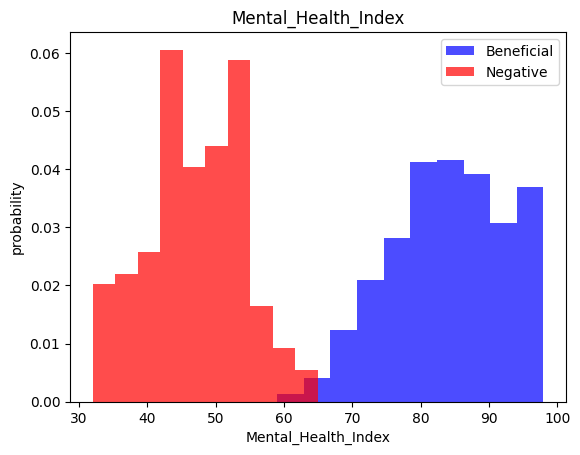

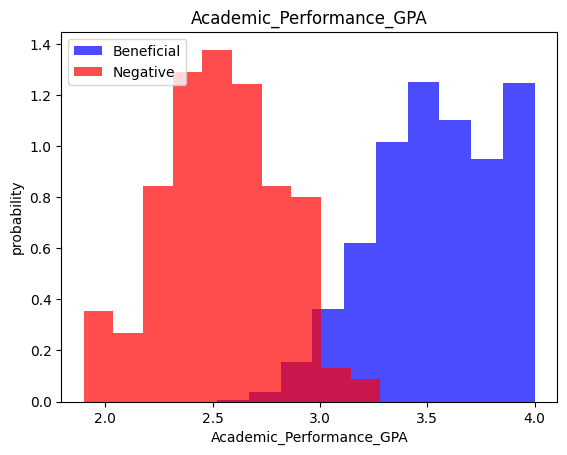

In [45]:
plot_cols = ["Daily_Usage_Hours", "Sleep_Duration_Hours", "Mental_Health_Index", "Academic_Performance_GPA"]

for label in plot_cols:
  plt.hist(df[df["Overall_Impact"] == 1][label], color='blue', label='Beneficial', alpha=0.7, density=True)
  plt.hist(df[df["Overall_Impact"] == 0][label], color='red', label='Negative', alpha=0.7, density=True)
  plt.title(label)
  plt.ylabel("probability")
  plt.xlabel(label)
  plt.legend()
  plt.show()

Train , Validation ans Test datasets


In [46]:
train , valid , test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])
def scale_dataset(dataframe , oversampler = False):
  x = dataframe[dataframe.columns[:-1]].values
  y = dataframe[dataframe.columns[-1]].values

  scaler = StandardScaler()
  x = scaler.fit_transform(x)
  if oversampler:
    ros = RandomOverSampler()
    x , y = ros.fit_resample(x,y)

  df = np.hstack((x,np.reshape(y ,(-1, 1))))
  return data, x,y

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [47]:
def scale_dataset_fixed(dataframe, numerical_cols, target_col, oversampler=False):
    x = dataframe[numerical_cols].values
    y = dataframe[target_col].values

    from sklearn.impute import SimpleImputer
    imputer = SimpleImputer(strategy='median')
    x = imputer.fit_transform(x)

    scaler = StandardScaler()
    x = scaler.fit_transform(x)

    if oversampler:
        ros = RandomOverSampler()
        x, y = ros.fit_resample(x, y)

    scaled_df = np.hstack((x, np.reshape(y, (-1, 1))))
    return scaled_df, x, y

num_cols = ["Daily_Usage_Hours", "Sleep_Duration_Hours", "Mental_Health_Index", "Academic_Performance_GPA"]
target = "Overall_Impact"



In [48]:
train_scaled, x_train, Y_train = scale_dataset_fixed(train, num_cols, target, oversampler=True)
valid_scaled, x_train, Y_train = scale_dataset_fixed(train, num_cols, target, oversampler=False)
test_scaled, x_train, Y_train = scale_dataset_fixed(train, num_cols, target, oversampler=False)

In [49]:
len(Y_train)

2700

In [50]:
sum(Y_train == 1)

np.int64(2191)

In [51]:
sum(Y_train == 0)

np.int64(90)

In [52]:
len(x_train)

2700

KNN(K-NEAREST NEIGHBORS)

In [53]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [54]:
knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(x_train, Y_train)

KNeighborsClassifier(n_neighbors=1)

In [58]:
y_pred_test = knn_model.predict(x_test)
print("KNN Test Classification Report:")
print(classification_report(Y_test, y_pred_test))

KNN Test Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        31
           1       0.98      0.99      0.98       722
           2       0.92      0.90      0.91       147

    accuracy                           0.97       900
   macro avg       0.94      0.93      0.94       900
weighted avg       0.97      0.97      0.97       900



In [41]:
y_pred = knn_model.predict(x_train)

In [42]:
y_pred

array([1, 1, 2, ..., 1, 1, 2])

In [59]:
Y_test

array([1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       2, 2, 2, 1, 1, 1, 1, 2, 1, 1, 0, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1,
       1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 1, 0, 1, 2, 1, 2, 1, 1, 1, 2, 1, 1,
       1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 2, 0, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 2, 1, 2, 1, 2, 0, 1, 1, 1, 1, 1, 1, 2, 0,

In [60]:
Y_train

array([1, 1, 1, ..., 1, 1, 1])

Naïve Bayes


SVM


In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(SVC(random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_svm.fit(x_train, Y_train)

print("Best Parameters:", grid_svm.best_params_)
best_model = grid_svm.best_estimator_
print("\nBest Model Test Report:")
print(classification_report(Y_test, best_model.predict(x_test)))

Best Parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}

Best Model Test Report:
              precision    recall  f1-score   support

           0       0.71      0.71      0.71        31
           1       0.94      0.98      0.96       722
           2       0.82      0.65      0.72       147

    accuracy                           0.92       900
   macro avg       0.82      0.78      0.80       900
weighted avg       0.91      0.92      0.91       900

